# Exercise: Can an encoder find malaria?

Each image is one blood cell. Some cells are **parasitized** (infected with malaria). Some are **uninfected**.

We used a pretrained encoder (DINOv2) to turn each image into a row of 768 numbers.

## Setup

In [1]:
library('tidymodels')
library('embed')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

Warning message:
“package ‘tidymodels’ was built under R version 4.5.2”


── Attaching packages ────────────────────────────────────── tidymodels 1.5.0 ──



✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.5      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.4      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.5.0 



Warning message:
“package ‘broom’ was built under R version 4.5.2”


Warning message:
“package ‘dials’ was built under R version 4.5.2”


Warning message:
“package ‘dplyr’ was built under R version 4.5.2”


... (8 outputs left out)

Warning message:
“package ‘tune’ was built under R version 4.5.2”


Warning message:
“package ‘yardstick’ was built under R version 4.5.2”


── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()



Warning message:
“package ‘embed’ was built under R version 4.5.2”


## 1. Load the data

Here are 6 example cells. The top row is parasitized. The bottom row is uninfected.

<img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C129P90ThinF_IMG_20151004_133921_cell_105.png" width="90"><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C189P150ThinF_IMG_20151203_140809_cell_133.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C52P13thinF_IMG_20150725_130013_cell_194.png" width="90"> <br><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C147P108ThinF_IMG_20151115_101156_cell_82.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C184P145ThinF_IMG_20151203_102405_cell_137.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C77P38ThinF_IMG_20150601_152941_cell_55.png" width="90">

The encoder already ran. Each row of `malaria` is one image. `e1` to `e768` are its embedding.

In [2]:
malaria <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_embeddings.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

malaria |> select(id, label, e1:e5) |> head()

`curl` package not installed, falling back to using `url()`


id,label,e1,e2,e3,e4,e5
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
C184P145ThinF_IMG_20151203_102405_cell_137,uninfected,0.0045,0.0178,0.0393,-0.0475,0.0563
C77P38ThinF_IMG_20150601_152941_cell_55,uninfected,0.0321,-0.0049,0.0702,-0.0556,-0.0220
C147P108ThinF_IMG_20151115_101156_cell_82,uninfected,0.0174,-0.0118,0.0692,-0.0476,-0.0041
C223ThinF_IMG_20151112_104410_cell_156,uninfected,0.0114,-0.0091,0.0375,-0.0590,0.0046
C92P53ThinF_IMG_20150821_151646_cell_32,uninfected,0.0226,0.0284,0.0138,-0.0545,0.0345
C83P44ThinF_IMG_20150817_134331_cell_194,uninfected,0.0194,-0.0292,0.0345,-0.0767,0.0011


In [3]:
malaria |> count(label)

label,n
<fct>,<int>
uninfected,1000
parasitized,1000


## 2. Visualize with UMAP

We cannot plot 768 dimensions at once. **UMAP** squeezes all the dimensions into 2 new columns, `UMAP1` and `UMAP2`. Similar images wil have similar `UMAP1` and `UMAP2` values.

Run the cell. It makes the 2 UMAP columns. (It takes a few seconds.)

In [4]:
set.seed(1)

umap_coords <- recipe(label ~ ., data = select(malaria, -id)) |>
    step_umap(all_predictors(), num_comp = 2) |>
    prep() |>
    bake(new_data = NULL)

umap_coords |> head()

label,UMAP1,UMAP2
<fct>,<dbl>,<dbl>
uninfected,-3.926122,0.8187736
uninfected,-1.617286,1.4352336
uninfected,-2.957548,-0.1688569
uninfected,-4.508528,0.9483520
uninfected,-1.222057,4.1709046
uninfected,-1.305344,2.6345544


**Your turn:** plot `UMAP1` against `UMAP2`. Color the points by `label`.

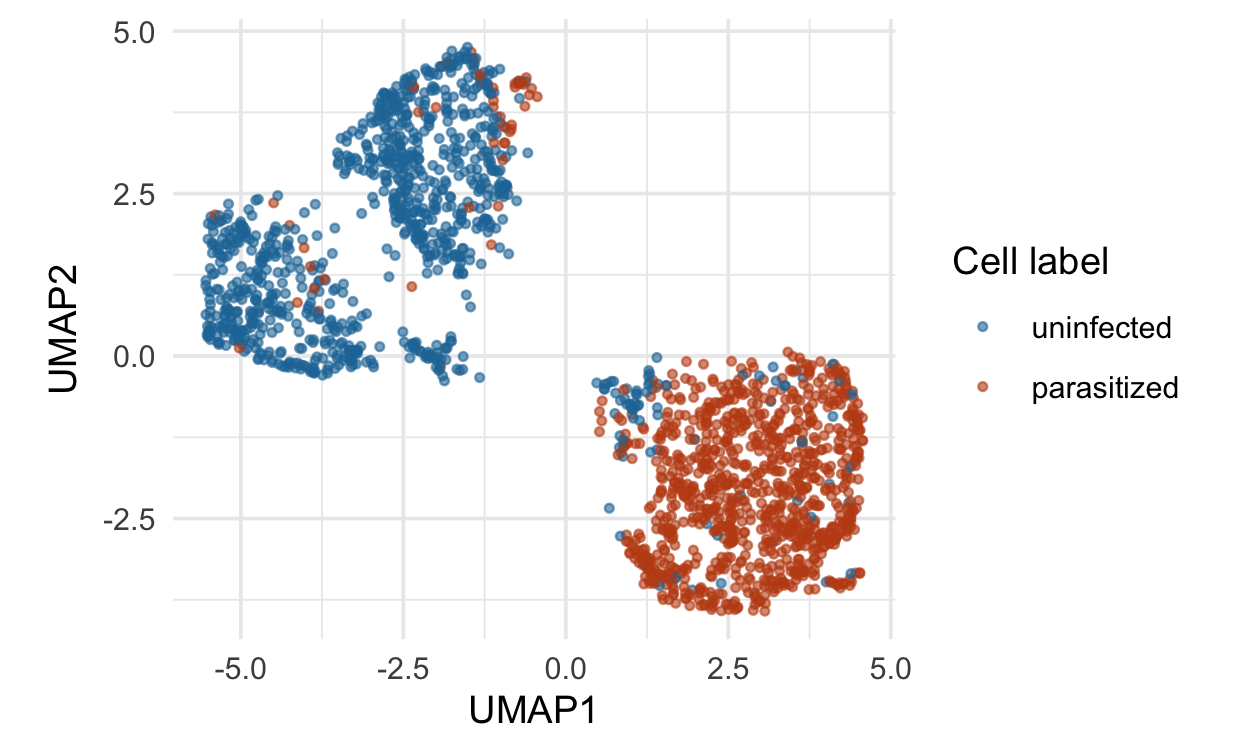

In [5]:
ggplot(umap_coords, aes(x = UMAP1, y = UMAP2, color = label)) +
    geom_point(size = 0.85, alpha = 0.6) +
    scale_color_manual(values = c(uninfected = "#2276A5", parasitized = "#C04C16")) +
    coord_equal() +
    labs(color = "Cell label") +
    theme_minimal(base_size = 11)

**Check:** do the two kinds of cell land in different places?

- Do you see clear groups? Are they perfectly separate?
- Which cells are hard to tell apart?

Most uninfected cells cluster on the left, and most parasitized cells cluster on the lower right. The groups overlap in places. For example, a pocket of blue points sits on the upper-left edge of the orange cluster. In those mixed regions, a cell's position on the plot is a poor guide to its label.

## 3. Split the data

Run this cell. Do not change it.

- `train`: half of the images. The model learns from these.
- `test`: the other half. The model has never seen these. We measure accuracy here.

In [6]:
set.seed(512)

split <- initial_split(malaria, prop = 0.5, strata = label)
train <- training(split) |> select(-id)
test  <- testing(split)  |> select(-id)

nrow(train)

[1] 1000

## 4. Pick a model

Pick a classifier model that we've worked with before (e.g. random forest). Fit it on `train`. Find the accuracy on `test`.

Options:

- `logistic_reg(penalty = 0.01, mixture = 0) |> set_engine('glmnet')`: logistic regression. We have 768 columns, so it needs a `penalty` (like in lecture 16).
- `rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')`: random forest.
- `mlp(hidden_units = 10, epochs = 500) |> set_mode('classification') |> set_engine('nnet', MaxNWts = 10000)`: neural net.

Use the formula `label ~ .` (all other embeddings columns are predictors).

In [7]:
forest <- rand_forest(trees = 200) |>
    set_mode("classification") |>
    set_engine("ranger", seed = 512, num.threads = 1)

embedding_fit <- fit(forest, label ~ ., data = train)

<details>
<summary>Hint: how do I find the accuracy?</summary>

1. `predict()` gives the predicted class for each test image.
2. `bind_cols()` puts it next to the true `label`.
3. `accuracy()` compares them.

```r
predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)
```

Here `fit` is the name of your fitted model. Use your own name.

</details>

In [8]:
score <- function(model, data) {
    predictions <- predict(model, new_data = data)
    tibble(
        correct = sum(predictions$.pred_class == data$label),
        total = nrow(data),
        accuracy = accuracy_vec(truth = data$label, estimate = predictions$.pred_class)
    )
}

embedding_train <- score(embedding_fit, train)
embedding_test <- score(embedding_fit, test)
bind_rows(train = embedding_train, test = embedding_test, .id = "split")

split,correct,total,accuracy
<chr>,<int>,<int>,<dbl>
train,999,1000,0.999
test,937,1000,0.937


**Check:** a good model gets about 0.93 to 0.95 on the test images.

- Why did you pick this model?
- Is the accuracy on `train` higher than on `test`? What does that tell you?

I chose a random forest because it can combine splits on several embedding features without assuming that a single straight boundary separates the classes. It classified 999 of 1,000 training images correctly (99.9%) and 937 of 1,000 held-out images correctly (93.7%). The 6.2 percentage-point gap suggests some overfitting. The test accuracy better represents performance on unseen images from this split.

## 5. Bonus: raw pixels

We also have the raw pixels for the same cells: `malaria_pixels.csv.gz`. That is 32 x 32 = 1,024 columns named `p1` to `p1024`.

Use the same split. Fit the same kind of model on the pixels. How does the test accuracy compare to the embeddings?

In [9]:
pixels <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_pixels.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

# Use the same split: train_pix has the same images as train
train_pix <- pixels |> filter(id %in% training(split)$id) |> select(-id)
test_pix  <- pixels |> filter(id %in% testing(split)$id)  |> select(-id)

stopifnot(
    !anyDuplicated(pixels$id),
    setequal(pixels$id, malaria$id),
    all(pixels$label == malaria$label[match(pixels$id, malaria$id)])
)

pixel_fit <- fit(forest, label ~ ., data = train_pix)
pixel_test <- score(pixel_fit, test_pix)
bind_rows(embeddings = embedding_test, pixels = pixel_test, .id = "predictors")

`curl` package not installed, falling back to using `url()`


predictors,correct,total,accuracy
<chr>,<int>,<int>,<dbl>
embeddings,937,1000,0.937
pixels,729,1000,0.729


*Your answer:* Which is better for finding malaria: pixels or embeddings? Why?

The embeddings worked better. On the same 1,000 test cells, the forest correctly classified 937 using embeddings and 729 using pixels (93.7% vs. 72.9%). One likely reason is that a dark spot can appear in different parts of a cell. Each raw pixel measures brightness at one fixed position, while the pretrained encoder can capture visual patterns that recur across positions.